# Robustness Checks

Four checks on the main results: the geometry of the joints behind the load and strength values, the effect of removing the study that supplies most of the thin bondlines, one-hot instead of label encoding for the categorical inputs, and trivial baselines with measured-only scores.

## Imports

In [1]:
import os
import sys
import json
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

sys.path.append('../src')
from zoo import TASKS, FAMILY, SEED, reg_models, clf_models, make_pipeline, grid_prefix, load_task

from sklearn.base import clone
from sklearn.model_selection import GroupKFold, GridSearchCV, train_test_split
from sklearn.metrics import r2_score, f1_score

warnings.filterwarnings('ignore')

## Settings

In [2]:
DATA = '../data/processed'
RESULTS = '../results'
OUT = f'{RESULTS}/sensitivity_checks'
os.makedirs(OUT, exist_ok=True)
os.makedirs('../figures', exist_ok=True)

CATEGORICAL = ['Adherend1_Class', 'Adherend2_Class', 'Fiber_Orientation_Class', 'Adhesive_Class',
               'Adhesive_Form', 'Filler1_Type', 'Filler2_Type', 'Joint_Type_Class']
maps = pd.read_csv(f'{DATA}/Label_Encoder_Maps.csv')
joint_type = dict(zip(maps[maps.Column == 'Joint_Type_Class'].Code, maps[maps.Column == 'Joint_Type_Class'].Category))

## Joint Geometry Behind the Load and Strength Values

Load and lap-shear strength are linked by the bonded area (overlap length times width). The table counts the records by joint type and shows how many values were calculated from the other quantity.

In [3]:
rows = []
for task in TASKS:
    df, X, y, groups, is_clf, target = load_task(task, root=DATA)
    d = df.assign(Joint_Type=X['Joint_Type_Class'].map(joint_type).values)
    g = d.groupby('Joint_Type').agg(records=('Row_ID', 'size'), studies=('Paper_ID', 'nunique'), calculated=('Target_Is_Derived', 'sum'))
    rows.append(g.reset_index().assign(Task=task))
geometry = pd.concat(rows)[['Task', 'Joint_Type', 'records', 'studies', 'calculated']]
geometry.to_csv(f'{OUT}/geometry_by_joint_type.csv', index=False)
geometry[~geometry.Task.str.endswith('FailureMode')]

,Task,Joint_Type,records,studies,calculated
0,CFRP_CFRP__MaxLoad,DLJ,87,3,0
1,CFRP_CFRP__MaxLoad,Finger,12,1,0
2,CFRP_CFRP__MaxLoad,SLJ,676,28,388
0,Composite_Composite__MaxLoad,DLJ,88,4,0
1,Composite_Composite__MaxLoad,Double strap,1,1,0
2,Composite_Composite__MaxLoad,Finger,12,1,0
3,Composite_Composite__MaxLoad,SLJ,951,42,400
4,Composite_Composite__MaxLoad,Single strap,1,1,0
5,Composite_Composite__MaxLoad,Stepped lap,1,1,0
0,CFRP_CFRP__LSS,SLJ,676,28,257


For single-lap records with both values reported, the ratio of the load to strength times area should be close to 1.

In [4]:
load = pd.read_csv(f'{DATA}/Composite_Composite/Composite_Composite__MaxLoad.csv')
strength = pd.read_csv(f'{DATA}/Composite_Composite/Composite_Composite__LSS.csv')
both = load.merge(strength[['Row_ID', 'LSS_MPa', 'Target_Is_Derived']], on='Row_ID', suffixes=('', '_S'))
both = both[(both.Joint_Type_Class == 4) & (both.Target_Is_Derived == 0) & (both.Target_Is_Derived_S == 0)]
both['ratio'] = both.MaxLoad_kN * 1000 / (both.Overlap_Length_mm * both.Joint_Width_mm * both.LSS_MPa)
summary = both.ratio.describe(percentiles=[0.25, 0.5, 0.75]).to_frame('load / (strength x area)')
summary.to_csv(f'{OUT}/load_strength_ratio.csv')
summary

,load / (strength x area)
count,191.000000
mean,1.013936
std,0.239003
min,0.184416
25%,0.968752
50%,1.001626
75%,1.037924
max,2.988914


## Removing the Study With Most of the Thin Bondlines

Study 64 supplies 135 of the 146 records with a 0.05 mm bondline and 135 of the 299 composite-composite records with a 12.5 mm overlap. Four tree models are refitted with and without it (hyper-parameters as selected in the main analysis), and the partial dependence on adhesive thickness and overlap length is evaluated on the records of all other studies.

In [5]:
def best_params(task, model):
    z = pd.read_csv(f'{RESULTS}/{task}__zoo_results.csv').set_index('Model')
    out = {}
    for k, v in json.loads(z.loc[model, 'Best_params']).items():
        try:
            out[k] = ast.literal_eval(v) if isinstance(v, str) else v
        except Exception:
            out[k] = v
    return out


def build(task, model, is_clf=False):
    estimator, grid, impute, scale_target = (clf_models() if is_clf else reg_models())[model]
    return make_pipeline(clone(estimator).set_params(**best_params(task, model)), impute, scale_target, is_clf)


THICKNESS = [0.05, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0]
OVERLAP = [12.5, 25, 50, 100]
STUDY = 64

In [6]:
rows = []
curves = {}
for task in ['Composite_Composite__LSS', 'CFRP_CFRP__LSS']:
    df, X, y, groups, is_clf, target = load_task(task, root=DATA)
    others = groups != STUDY
    for variant, fit_rows in [('with study 64', np.arange(len(y))), ('without study 64', np.where(others)[0])]:
        fitted = [build(task, m).fit(X.iloc[fit_rows], y[fit_rows]) for m in ['ET', 'RF', 'GB', 'LGBM']]
        for column, values in [('Adhesive_Thickness_mm', THICKNESS), ('Overlap_Length_mm', OVERLAP)]:
            mean = []
            for v in values:
                Z = X[others].copy()
                Z[column] = v
                mean.append(float(np.mean([m.predict(Z).mean() for m in fitted])))
            curves[(task, variant, column)] = mean
            rows.append(dict(Task=task, Variant=variant, Feature=column, **{str(v): round(p, 2) for v, p in zip(values, mean)}))
study_removal = pd.DataFrame(rows)
study_removal.to_csv(f'{OUT}/study_removal_partial_dependence.csv', index=False)
study_removal

,Task,Variant,Feature,0.05,0.1,0.2,0.3,0.5,1.0,2.0,12.5,25,50,100
0,Composite_Composite__LSS,with study 64,Adhesive_Thickness_mm,20.00,14.39,14.05,13.82,13.88,12.35,10.94,NaN,NaN,NaN,NaN
1,Composite_Composite__LSS,with study 64,Overlap_Length_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.69,15.13,16.56,16.55
2,Composite_Composite__LSS,without study 64,Adhesive_Thickness_mm,15.16,14.60,14.15,13.93,13.88,12.27,10.94,NaN,NaN,NaN,NaN
3,Composite_Composite__LSS,without study 64,Overlap_Length_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.84,15.15,17.26,17.25
4,CFRP_CFRP__LSS,with study 64,Adhesive_Thickness_mm,18.55,18.47,15.00,13.11,13.90,11.19,10.34,NaN,NaN,NaN,NaN
5,CFRP_CFRP__LSS,with study 64,Overlap_Length_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.91,16.68,17.50,17.50
6,CFRP_CFRP__LSS,without study 64,Adhesive_Thickness_mm,19.27,19.44,15.35,12.42,13.08,10.72,9.92,NaN,NaN,NaN,NaN
7,CFRP_CFRP__LSS,without study 64,Overlap_Length_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.50,16.39,17.81,17.81


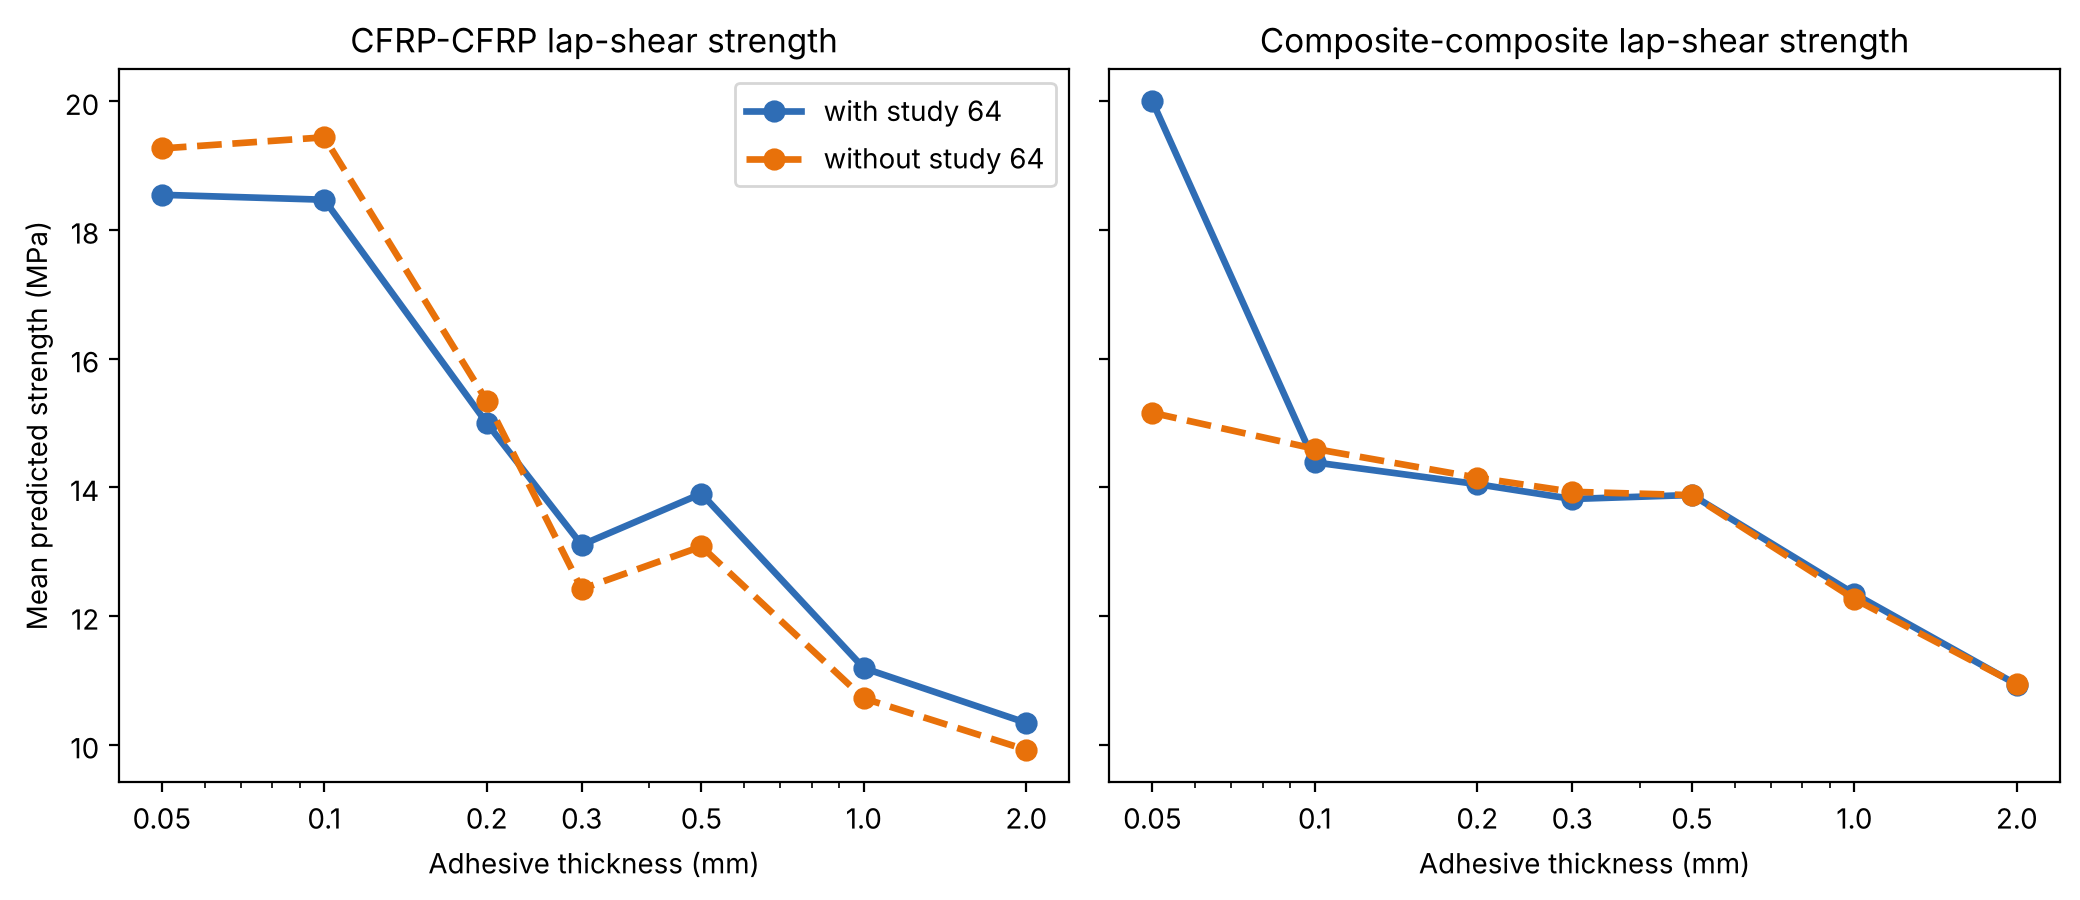

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
for ax, task, title in zip(axes, ['CFRP_CFRP__LSS', 'Composite_Composite__LSS'], ['CFRP-CFRP lap-shear strength', 'Composite-composite lap-shear strength']):
    for variant, color, style in [('with study 64', '#2F6DB5', '-'), ('without study 64', '#E8710A', '--')]:
        ax.plot(THICKNESS, curves[(task, variant, 'Adhesive_Thickness_mm')], style, color=color, lw=2.4, marker='o', ms=7, label=variant)
    ax.set_xscale('log')
    ax.set_xticks(THICKNESS)
    ax.set_xticklabels([str(v) for v in THICKNESS])
    ax.set_xlabel('Adhesive thickness (mm)')
    ax.set_title(title)
axes[0].set_ylabel('Mean predicted strength (MPa)')
axes[0].legend()
plt.tight_layout()
plt.savefig('../figures/fig24_study_removal_check.png', dpi=300, facecolor='white')
plt.show()

## One-Hot Encoding for the Non-Tree Models

Label encoding gives the categories an artificial order. The linear, kernel, neural-network, nearest-neighbour and Bayesian models are tuned and scored again with one-hot encoded categories, with the same split (seed 42), the same grouped grid search and the five further random splits of the main analysis.

In [8]:
REGRESSORS = ['OLS', 'Ridge', 'Lasso', 'ElasticNet', 'SVR', 'MLP', 'KNN', 'BayesRidge']
CLASSIFIERS = ['LogReg-L2', 'LogReg-L1', 'SVC', 'MLP', 'KNN', 'GNB']


def score(y_true, y_pred, is_clf):
    return f1_score(y_true, y_pred, average='macro') if is_clf else r2_score(y_true, y_pred)


def evaluate(task, model, X, y, groups, is_clf):
    estimator, grid, impute, scale_target = (clf_models() if is_clf else reg_models())[model]
    prefix = grid_prefix(scale_target, is_clf)
    idx = np.arange(len(y))
    train, test = train_test_split(idx, test_size=0.2, random_state=SEED)
    search = GridSearchCV(make_pipeline(clone(estimator), impute, scale_target, is_clf), {prefix + k: v for k, v in grid.items()},
                          cv=GroupKFold(min(5, len(set(groups[train])))), scoring='f1_macro' if is_clf else 'r2',
                          n_jobs=2, refit=False, error_score=np.nan)
    search.fit(X.iloc[train], y[train], groups=groups[train])
    params = {k[len(prefix):]: v for k, v in search.best_params_.items()}
    fit = lambda a: make_pipeline(clone(estimator).set_params(**params), impute, scale_target, is_clf).fit(X.iloc[a], y[a])
    main = score(y[test], fit(train).predict(X.iloc[test]), is_clf)
    further = []
    for seed in range(5):
        a, b = train_test_split(idx, test_size=0.2, random_state=seed)
        further.append(score(y[b], fit(a).predict(X.iloc[b]), is_clf))
    return main, float(np.mean(further))

In [9]:
rows = []
for task in TASKS:
    df, X, y, groups, is_clf, target = load_task(task, root=DATA)
    X_onehot = pd.get_dummies(X, columns=CATEGORICAL, dtype=float)
    stored = pd.read_csv(f'{RESULTS}/{task}__zoo_results.csv').set_index('Model')
    for model in (CLASSIFIERS if is_clf else REGRESSORS):
        label_main, label_further = evaluate(task, model, X, y, groups, is_clf)
        onehot_main, onehot_further = evaluate(task, model, X_onehot, y, groups, is_clf)
        rows.append(dict(Task=task, Model=model, Family=FAMILY[model],
                         Stored_main=stored.loc[model, 'Test_f1' if is_clf else 'Test_r2'],
                         Label_main=label_main, Onehot_main=onehot_main,
                         Label_five_splits=label_further, Onehot_five_splits=onehot_further))
    print(task, 'done', flush=True)
onehot = pd.DataFrame(rows)
onehot.to_csv(f'{OUT}/onehot_encoding.csv', index=False)
print('largest difference to the stored label-encoded score:', (onehot.Label_main - onehot.Stored_main).abs().max())
onehot.round(3)

CFRP_CFRP__MaxLoad done


Composite_Composite__MaxLoad done


CFRP_CFRP__LSS done


Composite_Composite__LSS done


CFRP_CFRP__FailureMode done


Composite_Composite__FailureMode done


largest difference to the stored label-encoded score: 4.947413029754433e-05


,Task,Model,Family,Stored_main,Label_main,Onehot_main,Label_five_splits,Onehot_five_splits
0,CFRP_CFRP__MaxLoad,OLS,Linear,0.859,0.859,0.856,0.875,0.873
1,CFRP_CFRP__MaxLoad,Ridge,Linear,0.637,0.637,0.674,0.681,0.718
2,CFRP_CFRP__MaxLoad,Lasso,Linear,0.844,0.844,0.842,0.855,0.855
3,CFRP_CFRP__MaxLoad,ElasticNet,Linear,0.713,0.713,0.741,0.753,0.779
4,CFRP_CFRP__MaxLoad,SVR,Kernel,0.835,0.835,0.851,0.892,0.928
5,CFRP_CFRP__MaxLoad,MLP,Neural net,0.869,0.869,0.841,0.875,0.873
6,CFRP_CFRP__MaxLoad,KNN,Nearest neighbour,0.890,0.891,0.853,0.955,0.910
7,CFRP_CFRP__MaxLoad,BayesRidge,Bayesian,0.855,0.855,0.854,0.872,0.869
8,Composite_Composite__MaxLoad,OLS,Linear,0.868,0.868,0.851,0.824,0.851
9,Composite_Composite__MaxLoad,Ridge,Linear,0.632,0.632,0.696,0.618,0.672


## Baselines and Measured Targets

The test error of the best model of each task is compared with a trivial baseline (training median for regression, majority class for classification), and the regression score is given separately for the test records with a measured and with a calculated target.

In [ ]:
import pickle
from sklearn.metrics import mean_absolute_error
rows = []
for task in TASKS:
    df, X, y, groups, is_clf, target = load_task(task, root=DATA)
    zoo_task = pd.read_csv(f'{RESULTS}/{task}__zoo_results.csv')
    best = zoo_task.sort_values('Test_f1' if is_clf else 'Test_r2', ascending=False).Model.iloc[0]
    p = pickle.load(open(f'{RESULTS}/{task}__predictions.pkl', 'rb'))[best]
    train, test = p['train_idx'], p['test_idx']
    y_test, pred = np.asarray(p['y_test']), np.asarray(p['pred_test'])
    if is_clf:
        majority = pd.Series(y[train]).mode()[0]
        rows.append(dict(Task=task, Model=best, Score=f1_score(y_test, pred, average='macro'),
                         Baseline=f1_score(y_test, np.full(len(y_test), majority), average='macro')))
    else:
        measured = df.iloc[test].Target_Is_Derived.values == 0
        mae, mae0 = mean_absolute_error(y_test, pred), np.abs(y_test - np.median(y[train])).mean()
        rows.append(dict(Task=task, Model=best, Score=r2_score(y_test, pred), MAE=mae, MAE_median_baseline=mae0,
                         MAE_reduction=1 - mae / mae0, R2_measured_only=r2_score(y_test[measured], pred[measured]),
                         R2_calculated_only=r2_score(y_test[~measured], pred[~measured])))
baseline = pd.DataFrame(rows)
baseline.to_csv(f'{OUT}/baseline_and_measured_only.csv', index=False)
baseline.round(3)